# Used Car Price Analysis

Guided training project by Jyotsna Konchada, revised with ChatGPT assistance. This version uses the uploaded dataset and documents its limitations. It is a learning exercise, not a pricing service.

The original saved notebook reported R² 0.32046 and RMSE 636316.77 after sequential outlier removal. The revised evaluation keeps valid expensive cars, so these results have different scopes and cannot be compared directly.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
def evaluate(name, actual, predicted):
    return {"model": name, "MAE": float(mean_absolute_error(actual, predicted)),
            "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
            "R2": float(r2_score(actual, predicted))}


## Load and validate data

Use named fields rather than column positions. Check duplicates without the artificial row identifier. Remove only exact duplicate records and invalid target values. Do not remove expensive cars merely because their prices are unusual. Data source, price currency, and snapshot date still require confirmation.

In [2]:
df = pd.read_csv(ROOT / "data/cars.csv")
print("Original shape:", df.shape)
print("Missing values:\n", df.isna().sum())
print("Duplicate records excluding Id:", df.drop(columns=["Id"], errors="ignore").duplicated().sum())
df = df.drop_duplicates(subset=[c for c in df.columns if c != "Id"]).copy()
df = df.loc[np.isfinite(df["price"]) & (df["price"] > 0)].copy()
print("Retained shape:", df.shape)
print(df[["price", "year", "distance_travelled(kms)"]].describe().round(2))


Original shape: (1725, 11)
Missing values:
 Id                         0
year                       0
brand                      0
full_model_name            0
model_name                 0
price                      0
distance_travelled(kms)    0
fuel_type                  0
city                       0
brand_rank                 0
car_age                    0
dtype: int64
Duplicate records excluding Id: 425
Retained shape: (1300, 11)
             price     year  distance_travelled(kms)
count      1300.00  1300.00                  1300.00
mean    1479682.69  2015.26                 55235.62
std     1720192.76     3.25                 47298.04
min       62500.00  1990.00                   350.00
25%      525000.00  2013.00                 30000.00
50%      842500.00  2016.00                 50227.00
75%     1796250.00  2018.00                 72000.00
max    14700000.00  2021.00                790000.00


## Explore patterns

A relationship in a scatterplot is an association, not proof of cause.

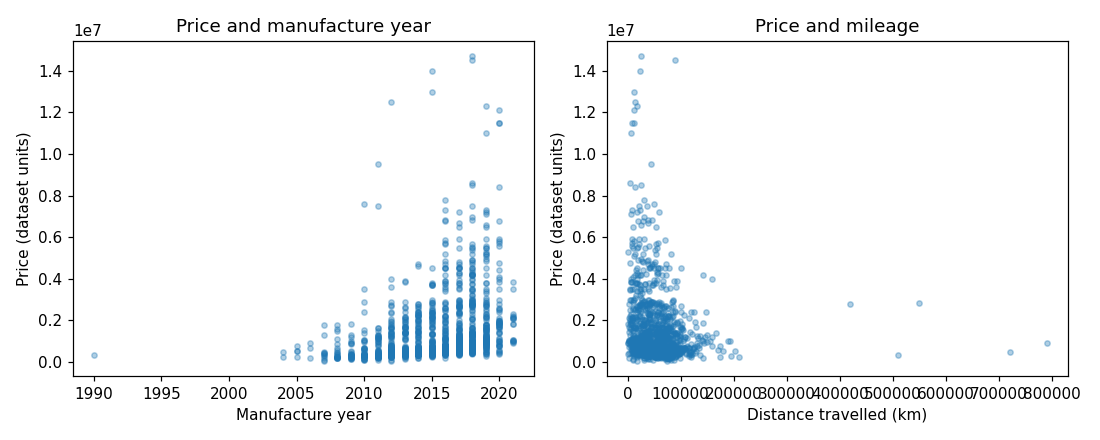

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(df["year"], df["price"], alpha=.35, s=12)
axes[0].set(xlabel="Manufacture year", ylabel="Price (dataset units)", title="Price and manufacture year")
axes[1].scatter(df["distance_travelled(kms)"], df["price"], alpha=.35, s=12)
axes[1].set(xlabel="Distance travelled (km)", ylabel="Price (dataset units)", title="Price and mileage")
fig.tight_layout()
fig.savefig(REPORTS / "price_patterns.png", dpi=150)
plt.show()


## Train and evaluate

Drop Id. Exclude brand_rank because its construction is undocumented. Use year instead of car_age because the latter depends on an unconfirmed reference year. One-hot encode brand, model, fuel type, and city, fitting transformations on training data only. Ridge uses a fixed alpha of 10 for this practice exercise; it was not selected using test results. Compare against a model that always predicts the training mean.

In [4]:
num = ["year", "distance_travelled(kms)"]
cat = ["brand", "model_name", "fuel_type", "city"]
X = df[num + cat]
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.30, random_state=10)
preprocess = ColumnTransformer([
    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
    ("category", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                           ("encode", OneHotEncoder(handle_unknown="ignore"))]), cat)
])
model = Pipeline([("preprocess", preprocess), ("regression", Ridge(alpha=10, solver="lsqr"))])
model.fit(X_train, y_train)
pred = model.predict(X_test)
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
metrics = pd.DataFrame([evaluate("Training mean baseline", y_test, baseline.predict(X_test)),
                        evaluate("One-hot Ridge regression", y_test, pred)])
print("Training/test rows:", len(X_train), len(X_test))
print(metrics.round(4).to_string(index=False))
print("Negative predictions:", int((pred < 0).sum()))
metrics.to_csv(REPORTS / "metrics.csv", index=False)
pd.DataFrame({"actual": y_test, "predicted": pred}).to_csv(REPORTS / "test_predictions.csv", index=False)


Training/test rows: 910 390
                   model          MAE         RMSE      R2
  Training mean baseline 1096229.7267 1690702.2431 -0.0014
One-hot Ridge regression  571761.2936 1139866.7501  0.5448
Negative predictions: 21


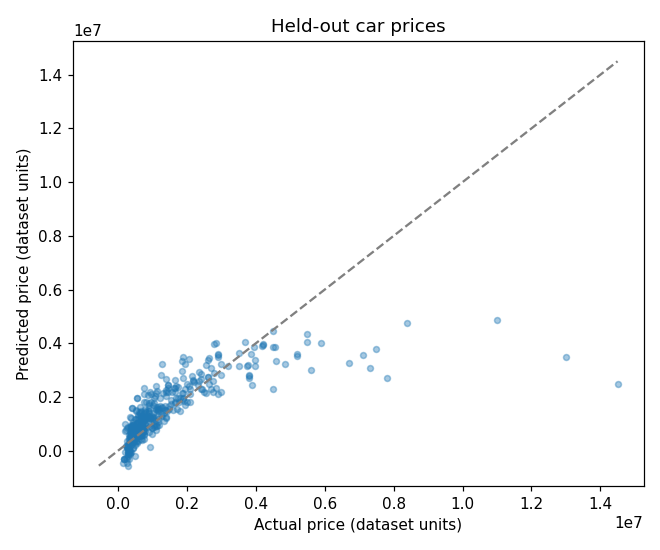

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, pred, alpha=.4, s=15)
lo, hi = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
ax.plot([lo, hi], [lo, hi], "--", color="gray")
ax.set(xlabel="Actual price (dataset units)", ylabel="Predicted price (dataset units)", title="Held-out car prices")
fig.tight_layout()
fig.savefig(REPORTS / "actual_vs_predicted.png", dpi=150)
plt.show()


## Limitations and next steps

This is one random split of a small historical dataset. Rare models and luxury vehicles can have large errors; predictions can be negative. No current market accuracy or causal price drivers are established. Confirm provenance, currency, and date, then evaluate cross-validation on training data and an untouched later-period dataset. Source work did not merge multiple datasets; do not claim a merge on the resume.